In [2]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import utils
import seaborn as sns


from utils import (
    calculate_technical_indicators,
    compare_results,
    evaluate_predictions,
    evaluate_torch_model,
    fit_arima,
    fit_standard_scaler,
    forecast_arima,
    grid_search_arima,
    load_fred_data,
    normalize_to_tensor,
    plot_dataset,
    plot_predictions_vs_targets,
    predict_and_store_log_return_model,
    predict_moving_average,
    predict_naive,
    prepare_data,
    split_data,
    store_model_prediction,
    train_torch_model,
    train_xgboost,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("model_results.json")
TARGET_COLUMN = "INR"
FEATURE_COLUMNS = ["JPY", "EUR", "FFER", "US10YY"]
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
EPOCHS = 100
BATCH_SIZE = 32
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cpu


/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/torch/cuda/__init__.py:188: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [3]:
full_df = prepare_data(load_fred_data(DATA_DIR))
full_df["TARGET_NEXT"] = full_df[TARGET_COLUMN].shift(-1)
full_df = full_df.dropna(subset=["TARGET_NEXT"])

train_df, val_df, test_df = split_data(
    full_df,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

full_df.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT
observation_date,,,,,,
1999-01-04,42.60,112.15,1.1812,5.04,4.69,42.56
1999-01-05,42.56,111.15,1.1760,4.54,4.74,42.55
1999-01-06,42.55,112.78,1.1636,4.23,4.73,42.55
1999-01-07,42.55,111.69,1.1672,4.49,4.77,42.55
1999-01-08,42.55,111.52,1.1554,4.74,4.86,42.55


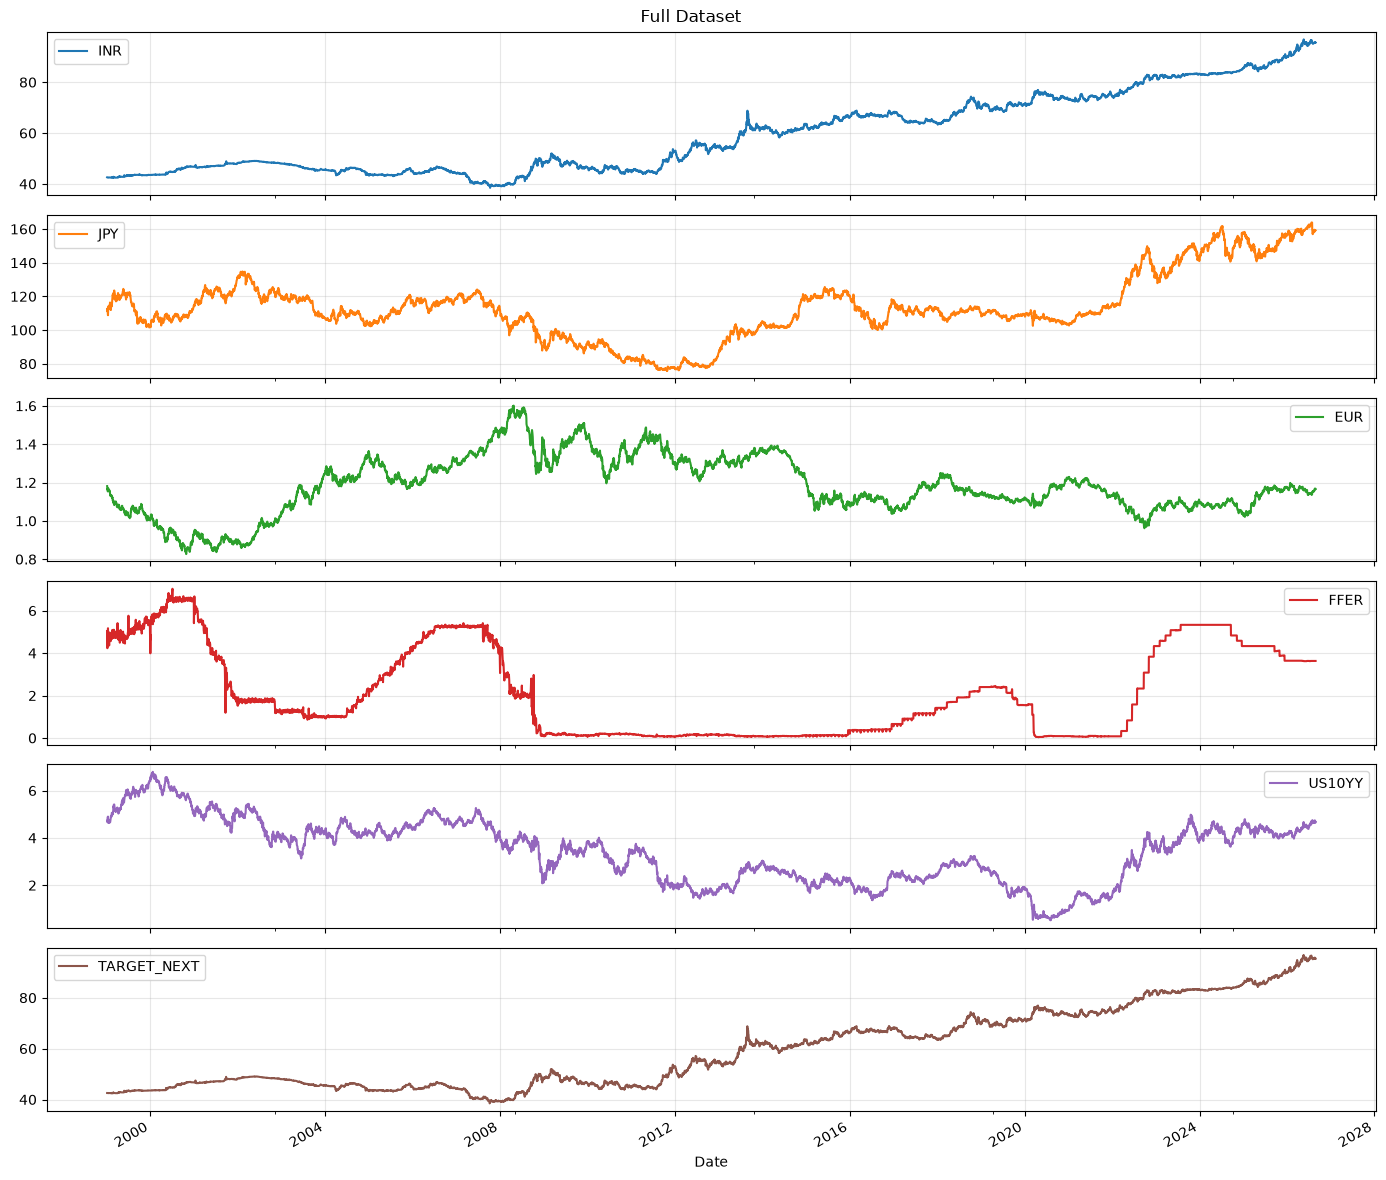

Train: (5524, 6), validation: (690, 6), test: (691, 6)


In [4]:
plot_dataset(full_df)
print(f"Train: {train_df.shape}, validation: {val_df.shape}, test: {test_df.shape}")

## Baseline and ARIMA

Naive: {'mae': 0.1493805826271353, 'mse': 0.07776622105608079, 'rmse': 0.27886595535504294, 'directional_accuracy': 53.08709034944776, 'correct_days': 2932, 'total_days': 5523}
Moving average: {'mae': 0.11185312760039676, 'mse': 0.07249965294511787, 'rmse': 0.2692575958912169, 'directional_accuracy': 78.20025348542458, 'correct_days': 4319, 'total_days': 5523}


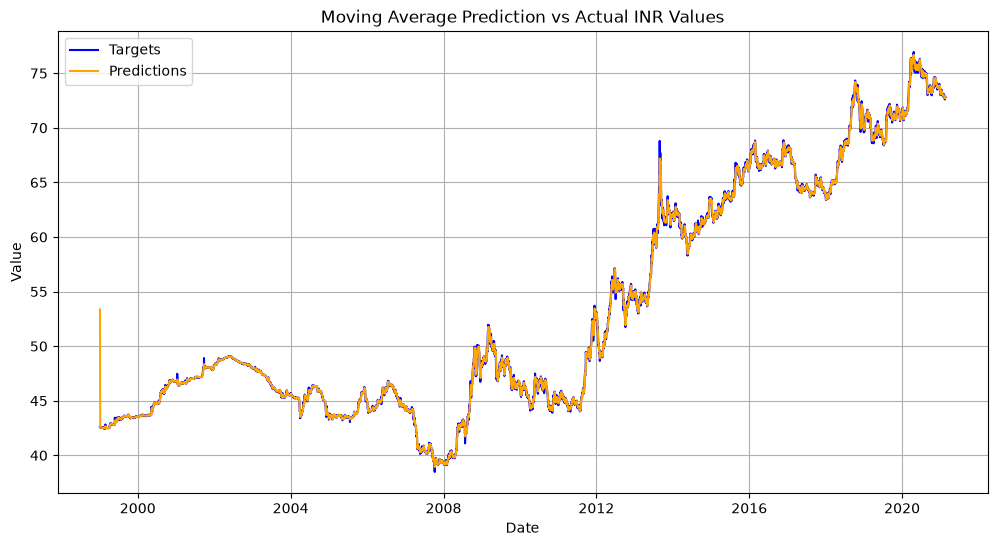

In [4]:
naive_predictions = predict_naive(train_df, TARGET_COLUMN)
moving_average_predictions = predict_moving_average(train_df, target_column=TARGET_COLUMN)

naive_metrics = evaluate_predictions(naive_predictions, train_df[TARGET_COLUMN])
moving_average_metrics = evaluate_predictions(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "Naive",
    naive_predictions,
    naive_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Moving Average",
    moving_average_predictions,
    moving_average_metrics,
    "train",
)
print("Naive:", naive_metrics)
print("Moving average:", moving_average_metrics)
plot_predictions_vs_targets(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
    x_values=train_df.index,
    title="Moving Average Prediction vs Actual INR Values",
)

/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maxi

        order       mae          aic
13  (2, 0, 1)  1.205977  1119.841793
7   (1, 0, 1)  3.186553   969.581745
12  (2, 0, 0)  3.973017   983.011763
8   (1, 0, 2)  4.847509  1019.785826
14  (2, 0, 2)  5.150125  1196.039656
Best ARIMA order: (2, 0, 1)


/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'mae': 1.205977239748999, 'mse': 2.5201668038105103, 'rmse': 1.5875033240313263, 'directional_accuracy': 53.12046444121916, 'correct_days': 366, 'total_days': 689}


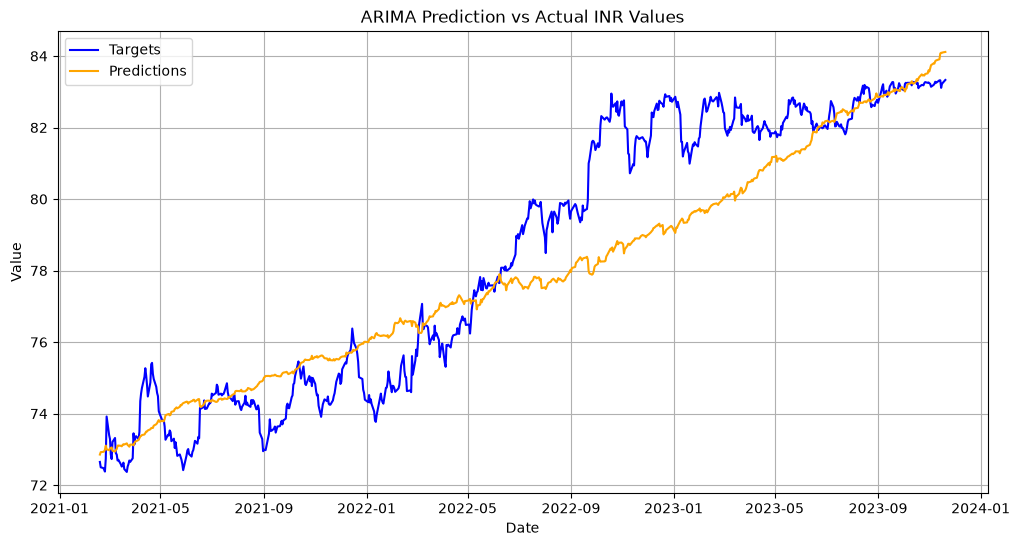

In [5]:
search_results, best_order = grid_search_arima(
    train_df,
    val_df,
    FEATURE_COLUMNS,
    p_values=range(0, 3),
    d_values=range(0, 2),
    q_values=range(0, 3),
    target_column=TARGET_COLUMN,
)
print(search_results.head())
print(f"Best ARIMA order: {best_order}")
arima_model = fit_arima(train_df, FEATURE_COLUMNS, best_order, TARGET_COLUMN)
arima_train_predictions = arima_model.predict(
    start=0,
    end=len(train_df) - 1,
    exog=train_df[FEATURE_COLUMNS],
)
arima_predictions, arima_metrics = forecast_arima(
    arima_model,
    val_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
arima_train_metrics = evaluate_predictions(
    arima_train_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_train_predictions,
    arima_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_predictions,
    arima_metrics,
    "validation",
)
print(arima_metrics)
plot_predictions_vs_targets(
    arima_predictions,
    val_df[TARGET_COLUMN],
    x_values=val_df.index,
    title="ARIMA Prediction vs Actual INR Values",
)

## XGBoost

[0]	validation_0-rmse:10.25423	validation_1-rmse:25.29038	validation_2-rmse:34.46778
[100]	validation_0-rmse:1.06208	validation_1-rmse:26.31129	validation_2-rmse:43.11082
[200]	validation_0-rmse:0.69558	validation_1-rmse:26.42453	validation_2-rmse:43.53154
[300]	validation_0-rmse:0.59379	validation_1-rmse:26.43008	validation_2-rmse:43.55042
[400]	validation_0-rmse:0.53247	validation_1-rmse:26.44760	validation_2-rmse:43.60511
[499]	validation_0-rmse:0.48495	validation_1-rmse:26.44523	validation_2-rmse:43.59878
{'mae': 43.44264259945639, 'mse': 1900.8537325051705, 'rmse': 43.59878131903655, 'directional_accuracy': 44.927536231884055, 'correct_days': 310, 'total_days': 690}


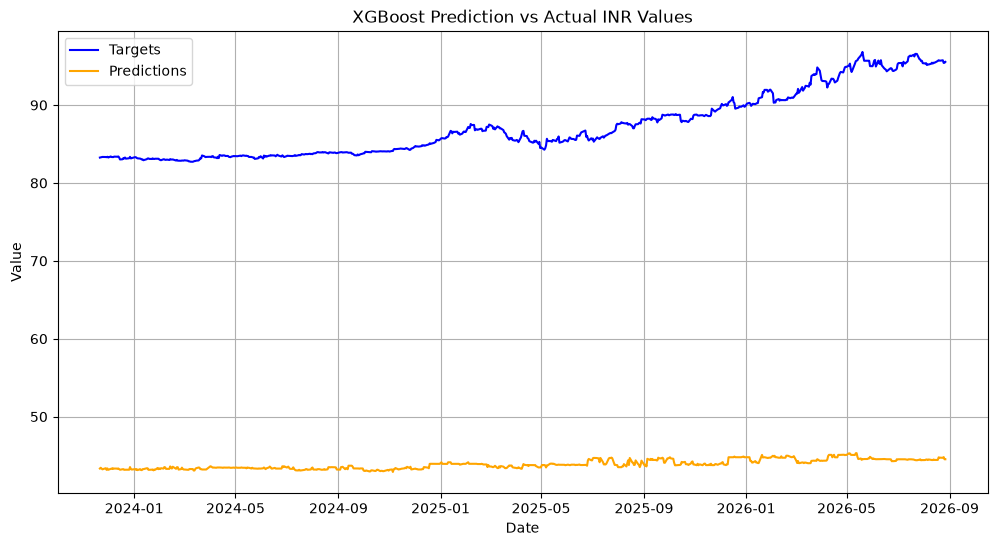

In [6]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
xgb_model = train_xgboost(
    xgb_model,
    train_df,
    val_df,
    test_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
xgb_train_predictions = xgb_model.predict(train_df[FEATURE_COLUMNS])
xgb_test_predictions = xgb_model.predict(test_df[FEATURE_COLUMNS])
xgb_train_metrics = evaluate_predictions(
    xgb_train_predictions,
    train_df[TARGET_COLUMN],
)
xgb_metrics = evaluate_predictions(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_train_predictions,
    xgb_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_test_predictions,
    xgb_metrics,
    "test",
)
print(xgb_metrics)
plot_predictions_vs_targets(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
    x_values=test_df.index,
    title="XGBoost Prediction vs Actual INR Values",
)

In [5]:
baseline_feature_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
X_train = torch.tensor(
    train_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_train = torch.tensor(
    train_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_val = torch.tensor(
    val_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_val = torch.tensor(
    val_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_test = torch.tensor(
    test_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_test = torch.tensor(
    test_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

linear_model = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
linear_optimizer = optim.Adam(linear_model.parameters(), lr=0.01)
linear_losses = train_torch_model(
    linear_model,
    linear_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

deep_model = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, OUTPUT_FEATURES),
)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.01)
deep_losses = train_torch_model(
    deep_model,
    deep_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

with torch.no_grad():
    linear_train_predictions = linear_model(X_train)
    linear_test_predictions = linear_model(X_test)
    deep_train_predictions = deep_model(X_train)
    deep_test_predictions = deep_model(X_test)

linear_train_metrics = evaluate_predictions(linear_train_predictions, y_train)
linear_metrics = evaluate_predictions(linear_test_predictions, y_test)
deep_train_metrics = evaluate_predictions(deep_train_predictions, y_train)
deep_metrics = evaluate_predictions(deep_test_predictions, y_test)

store_model_prediction(
    model_results,
    "Linear Regression",
    linear_train_predictions,
    linear_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Linear Regression",
    linear_test_predictions,
    linear_metrics,
    "test",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_train_predictions,
    deep_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_test_predictions,
    deep_metrics,
    "test",
)

print(f"Linear Regression test metrics: {linear_metrics}")
print(f"Deep Learning test metrics: {deep_metrics}")

Epoch 10/100, Train Loss: 155.2800, Val Loss: 299.1541
Epoch 20/100, Train Loss: 160.5745, Val Loss: 111.6766
Epoch 30/100, Train Loss: 130.9530, Val Loss: 216.0067
Epoch 40/100, Train Loss: 121.7027, Val Loss: 275.9749
Epoch 50/100, Train Loss: 107.9314, Val Loss: 195.6216
Epoch 60/100, Train Loss: 97.4876, Val Loss: 166.2344
Epoch 70/100, Train Loss: 86.9428, Val Loss: 175.2794
Epoch 80/100, Train Loss: 77.3904, Val Loss: 155.8917
Epoch 90/100, Train Loss: 68.6288, Val Loss: 136.1082
Epoch 100/100, Train Loss: 60.6581, Val Loss: 128.0523
Epoch 10/100, Train Loss: 430.6611, Val Loss: 31.5454
Epoch 20/100, Train Loss: 163.2187, Val Loss: 365.0745
Epoch 30/100, Train Loss: 85.0953, Val Loss: 75.7592
Epoch 40/100, Train Loss: 51.0183, Val Loss: 67.4911
Epoch 50/100, Train Loss: 33.6372, Val Loss: 81.7824
Epoch 60/100, Train Loss: 18.1568, Val Loss: 17.1702
Epoch 70/100, Train Loss: 6.7359, Val Loss: 7.1756
Epoch 80/100, Train Loss: 2.5937, Val Loss: 4.7215
Epoch 90/100, Train Loss: 1.761

## Technical indicators

In [6]:
technical_data = calculate_technical_indicators(full_df).dropna()
technical_data["TARGET_NEXT"] = technical_data["Log_Returns"].shift(-1)
technical_data = technical_data.dropna(subset=["TARGET_NEXT"])
technical_data.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT,MA_5,MA_10,MA_30,MA_50,...,EMA_50,EMA_100,RSI,BB_Middle,BB_Upper,BB_Lower,Volatility,ATR_14_proxy,ATR_%_proxy,Log_Returns
observation_date,,,,,,,,,,,,,,,,,,,,,
1999-05-25,42.80,122.88,1.0587,4.80,5.49,0.003499,42.800,42.796,42.831000,42.7324,...,42.748324,42.686452,50.000000,42.8105,42.873571,42.747429,0.031535,0.010000,0.023364,0.000000
1999-05-26,42.95,122.03,1.0471,4.81,5.55,0.011574,42.830,42.811,42.834333,42.7414,...,42.756233,42.691671,75.862069,42.8130,42.892763,42.733237,0.039881,0.020714,0.048229,0.003499
1999-05-27,43.45,121.27,1.0439,4.87,5.62,-0.006465,42.960,42.876,42.852667,42.7604,...,42.783440,42.706688,91.139241,42.8425,43.138571,42.546429,0.148035,0.056429,0.129870,0.011574
1999-05-28,43.17,120.88,1.0422,4.61,5.64,-0.003946,43.034,42.910,42.866667,42.7738,...,42.798599,42.715862,67.289720,42.8590,43.189289,42.528711,0.165144,0.076429,0.177041,-0.006465
1999-06-01,43.00,120.75,1.0449,4.78,5.78,0.000000,43.074,42.934,42.868333,42.7838,...,42.806497,42.721489,58.064516,42.8665,43.202688,42.530312,0.168094,0.088571,0.205980,-0.003946


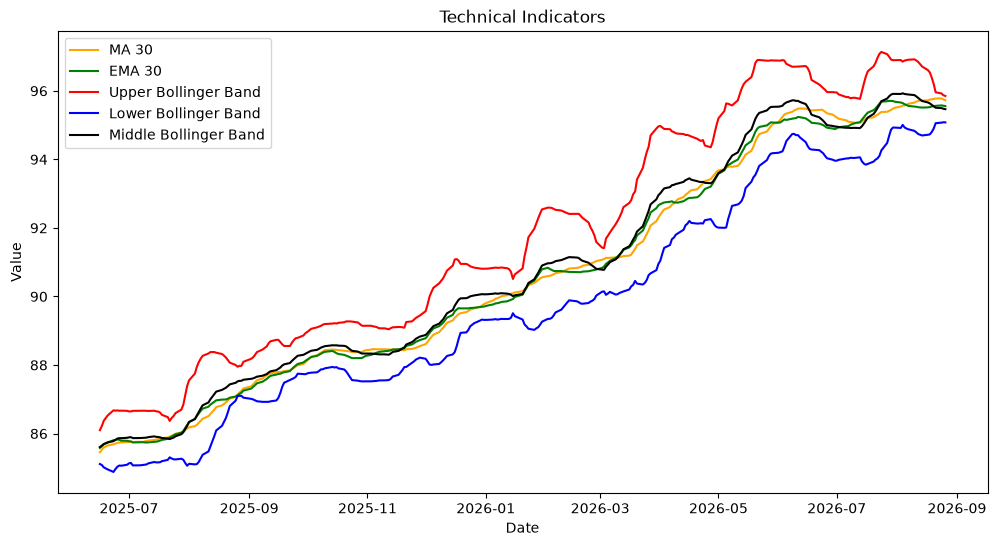

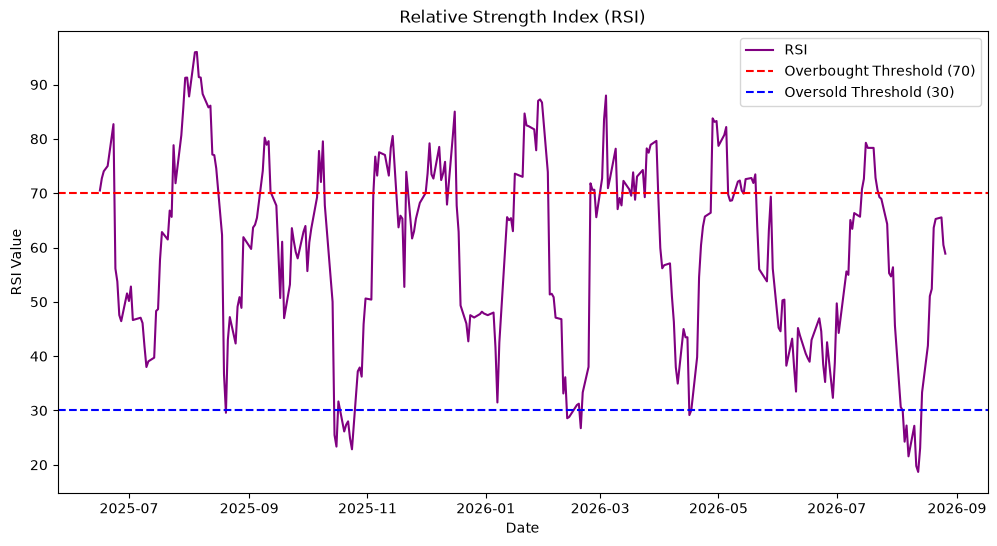

In [7]:
# Plot data with technical indicators - MA30, EMA30, RSI, bollinger bands
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["MA_30"], label="MA 30", color="orange")
plt.plot(technical_data[-300:].index, technical_data[-300:]["EMA_30"], label="EMA 30", color="green")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Upper"], label="Upper Bollinger Band", color="red")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Lower"], label="Lower Bollinger Band", color="blue")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Middle"], label="Middle Bollinger Band", color="black")
plt.title("Technical Indicators")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()

## RSI
plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["RSI"], label="RSI", color="purple")
plt.title("Relative Strength Index (RSI)")
plt.xlabel("Date")
plt.ylabel("RSI Value")
plt.axhline(70, color="red", linestyle="--", label="Overbought Threshold (70)")
plt.axhline(30, color="blue", linestyle="--", label="Oversold Threshold (30)")
plt.legend()
plt.show()

### Analysis of tecchnical data

<Axes: >

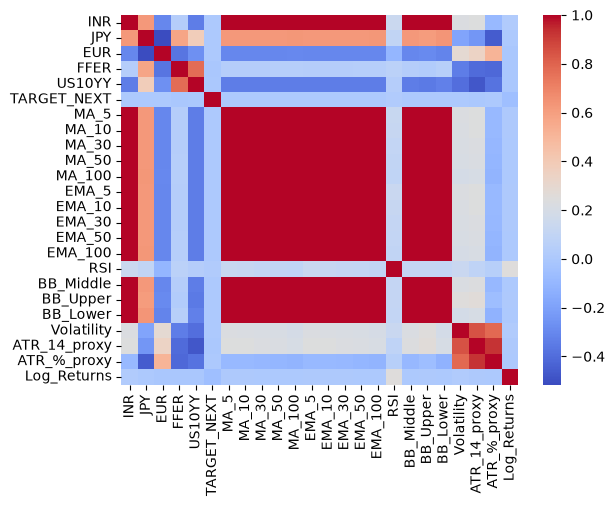

In [8]:
##  code to plot the technical indicators

sns.heatmap(technical_data.corr(), cmap="coolwarm")

In [9]:
NUM_INPUT_FEATURES = len(FEATURE_COLUMNS) + 1 + 12  # Original features + target + technical indicators
OUTPUT_FEATURES = 1  # Predicting the next price

train_df_ta, val_df_ta, test_df_ta = split_data(
    technical_data,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

In [10]:
ta_columns = [
    "MA_5",
    "MA_10",
    "MA_30",
    "MA_50",
    "MA_100",
    "EMA_5",
    "EMA_10",
    "EMA_30",
    "EMA_50",
    "EMA_100",
    "RSI",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volatility",
    "ATR_14_proxy",
    "ATR_%_proxy",
    "Log_Returns",
]

all_features = FEATURE_COLUMNS + [TARGET_COLUMN] + ta_columns

In [11]:
TARGET_COLUMN = "INR"
technical_target_column = "TARGET_NEXT"

In [12]:
feature_scaler = fit_standard_scaler(train_df_ta, all_features)

train_targets = train_df_ta["TARGET_NEXT"]
val_targets = val_df_ta["TARGET_NEXT"]
test_targets = test_df_ta["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_ta, feature_scaler, all_features)
X_val = normalize_to_tensor(val_df_ta, feature_scaler, all_features)
X_test = normalize_to_tensor(test_df_ta, feature_scaler, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [13]:
model_linear_ta = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
model_linear_ta_optimizer = optim.Adam(
    model_linear_ta.parameters(),
    lr=0.001,
)
model_linear_ta_loss_function = nn.MSELoss()

In [14]:
EPOCHS = 100

model_linear_ta_losses = train_torch_model(
    model_linear_ta,
    model_linear_ta_optimizer,
    model_linear_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.0783, Val Loss: 0.4957
Epoch 20/100, Train Loss: 1.0636, Val Loss: 0.4808
Epoch 30/100, Train Loss: 1.0516, Val Loss: 0.4604
Epoch 40/100, Train Loss: 1.0419, Val Loss: 0.4498
Epoch 50/100, Train Loss: 1.0340, Val Loss: 0.4386
Epoch 60/100, Train Loss: 1.0276, Val Loss: 0.4306
Epoch 70/100, Train Loss: 1.0223, Val Loss: 0.4251
Epoch 80/100, Train Loss: 1.0179, Val Loss: 0.4213
Epoch 90/100, Train Loss: 1.0144, Val Loss: 0.4190
Epoch 100/100, Train Loss: 1.0114, Val Loss: 0.4177


Test MAE: 0.1484, Test MSE: 0.0536


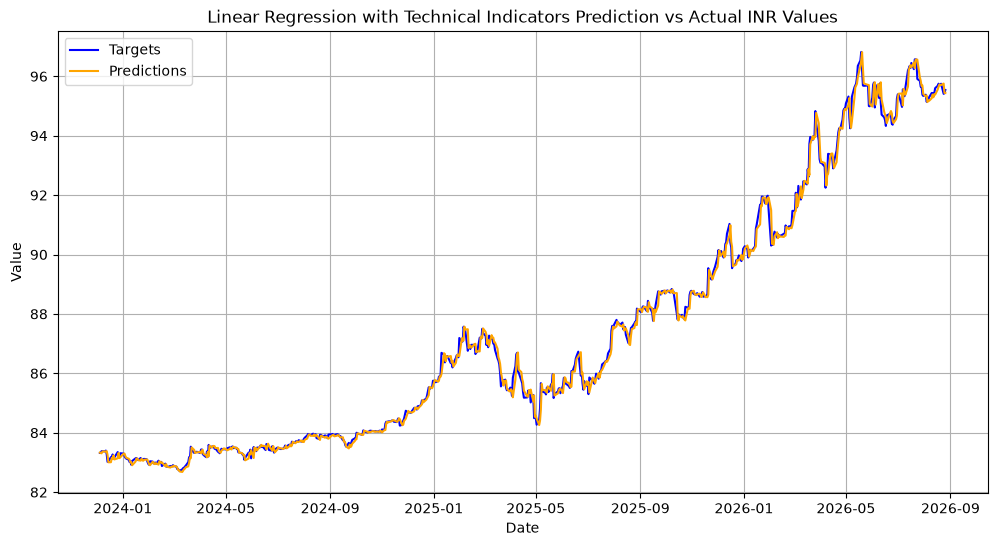

In [15]:
linear_ta_prediction_results = predict_and_store_log_return_model(
    model=model_linear_ta,
    model_name="Linear Regression with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_linear_ta = linear_ta_prediction_results["train_predictions"]
predicted_prices_linear_ta = linear_ta_prediction_results["test_predictions"]
actual_train_prices_ta = linear_ta_prediction_results["train_actual_prices"]
actual_prices_ta = linear_ta_prediction_results["test_actual_prices"]
linear_ta_train_metrics = linear_ta_prediction_results["train_metrics"]
linear_ta_metrics = linear_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {linear_ta_metrics['mae']:.4f}, "
    f"Test MSE: {linear_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_linear_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Linear Regression with Technical Indicators Prediction vs Actual INR Values",
)

In [16]:
model_dl_ta = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
model_dl_ta_optimizer = optim.Adam(
    model_dl_ta.parameters(),
    lr=0.001,
)
model_dl_ta_loss_function = nn.MSELoss()

In [17]:
train_losses_dl_ta = train_torch_model(
    model_dl_ta,
    model_dl_ta_optimizer,
    model_dl_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.0024, Val Loss: 0.4422
Epoch 20/100, Train Loss: 0.9968, Val Loss: 0.4099
Epoch 30/100, Train Loss: 0.9927, Val Loss: 0.4121
Epoch 40/100, Train Loss: 0.9888, Val Loss: 0.4111
Epoch 50/100, Train Loss: 0.9853, Val Loss: 0.4099
Epoch 60/100, Train Loss: 0.9821, Val Loss: 0.4099
Epoch 70/100, Train Loss: 0.9793, Val Loss: 0.4104
Epoch 80/100, Train Loss: 0.9763, Val Loss: 0.4105
Epoch 90/100, Train Loss: 0.9733, Val Loss: 0.4103
Epoch 100/100, Train Loss: 0.9698, Val Loss: 0.4100


Test MAE: 0.1455, Test MSE: 0.0534


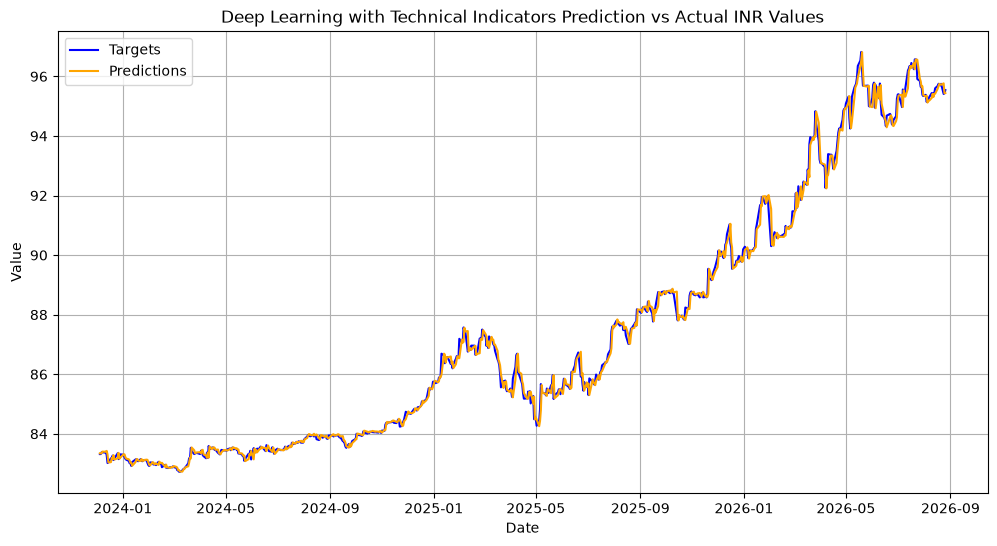

In [18]:
deep_ta_prediction_results = predict_and_store_log_return_model(
    model=model_dl_ta,
    model_name="Deep Learning with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_ta = deep_ta_prediction_results["train_predictions"]
predicted_prices_ta = deep_ta_prediction_results["test_predictions"]
actual_train_prices_ta = deep_ta_prediction_results["train_actual_prices"]
actual_prices_ta = deep_ta_prediction_results["test_actual_prices"]
deep_ta_train_metrics = deep_ta_prediction_results["train_metrics"]
deep_ta_metrics = deep_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_ta_metrics['mae']:.4f}, "
    f"Test MSE: {deep_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators Prediction vs Actual INR Values",
)

## ADD NEW TEMPORAL FEATURES

In [19]:
TEMPORAL_FEATURES_NUMBER = 5  # Number of temporal features to include

In [20]:
import pandas as pd

def create_temporal_features(df, target_columns=None, num_features=5):
    """Add lagged temporal features"""
    df = df.copy()

    if target_columns is None:
        target_columns = [
            column for column in df.columns
            if column != "TARGET_NEXT"
        ]

    lagged_features = [
        df[target_columns]
        .shift(lag)
        .add_suffix(f"_lag_{lag}")
        for lag in range(1, num_features + 1)
    ]

    return pd.concat([df, *lagged_features], axis=1)


In [21]:
train_df_temp = create_temporal_features(
    train_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
val_df_temp = create_temporal_features(
    val_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
test_df_temp = create_temporal_features(
    test_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()

In [22]:
train_df_temp.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5439 entries, 1999-06-02 to 2021-03-16
Columns: 139 entries, INR to Log_Returns_lag_5
dtypes: float64(139)
memory usage: 5.8 MB


In [23]:
temporal_features = all_features + [
    f"{feature}_lag_{lag}"
    for feature in all_features
    for lag in range(1, TEMPORAL_FEATURES_NUMBER + 1)
]

feature_scaler_temp = fit_standard_scaler(train_df_temp, temporal_features)

train_targets = train_df_temp["TARGET_NEXT"]
val_targets = val_df_temp["TARGET_NEXT"]
test_targets = test_df_temp["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_temp, feature_scaler_temp, temporal_features)
X_val = normalize_to_tensor(val_df_temp, feature_scaler_temp, temporal_features)
X_test = normalize_to_tensor(test_df_temp, feature_scaler_temp, temporal_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [24]:
model_dl_temp = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(32, 1)
)
model_dl_temp_optimizer = optim.Adam(
    model_dl_temp.parameters(),
    lr=0.001,
)
model_dl_temp_loss_function = nn.MSELoss()

In [25]:
train_losses_dl_temp = train_torch_model(
    model_dl_temp,
    model_dl_temp_optimizer,
    model_dl_temp_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9950, Val Loss: 0.4126
Epoch 20/100, Train Loss: 0.9897, Val Loss: 0.4149
Epoch 30/100, Train Loss: 0.9846, Val Loss: 0.4161
Epoch 40/100, Train Loss: 0.9775, Val Loss: 0.4143
Epoch 50/100, Train Loss: 0.9722, Val Loss: 0.4170
Epoch 60/100, Train Loss: 0.9677, Val Loss: 0.4209
Epoch 70/100, Train Loss: 0.9564, Val Loss: 0.4239
Epoch 80/100, Train Loss: 0.9467, Val Loss: 0.4232
Epoch 90/100, Train Loss: 0.9400, Val Loss: 0.4315
Epoch 100/100, Train Loss: 0.9303, Val Loss: 0.4303


Test MAE: 0.1682, Test MSE: 0.0580


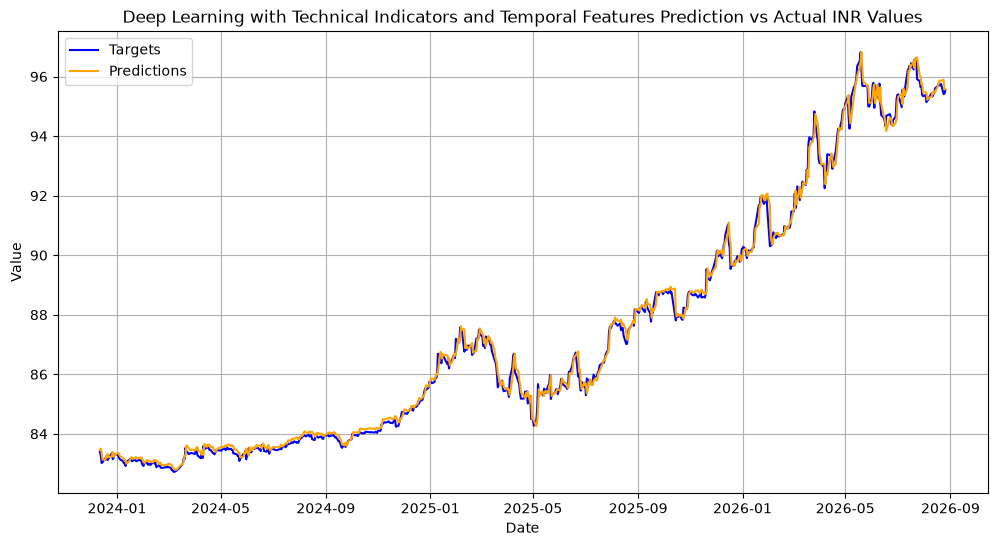

In [26]:
deep_temp_prediction_results = predict_and_store_log_return_model(
    model=model_dl_temp,
    model_name="Deep Learning with Technical Indicators and Temporal Features",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_temp["INR"].values,
    test_current_prices=test_df_temp["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_temp = deep_temp_prediction_results["train_predictions"]
predicted_prices_temp = deep_temp_prediction_results["test_predictions"]
actual_train_prices_temp = deep_temp_prediction_results["train_actual_prices"]
actual_prices_temp = deep_temp_prediction_results["test_actual_prices"]
deep_temp_train_metrics = deep_temp_prediction_results["train_metrics"]
deep_temp_metrics = deep_temp_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_temp_metrics['mae']:.4f}, "
    f"Test MSE: {deep_temp_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_temp,
    actual_prices_temp,
    x_values=test_df_temp.index,
    title="Deep Learning with Technical Indicators and Temporal Features Prediction vs Actual INR Values",
)

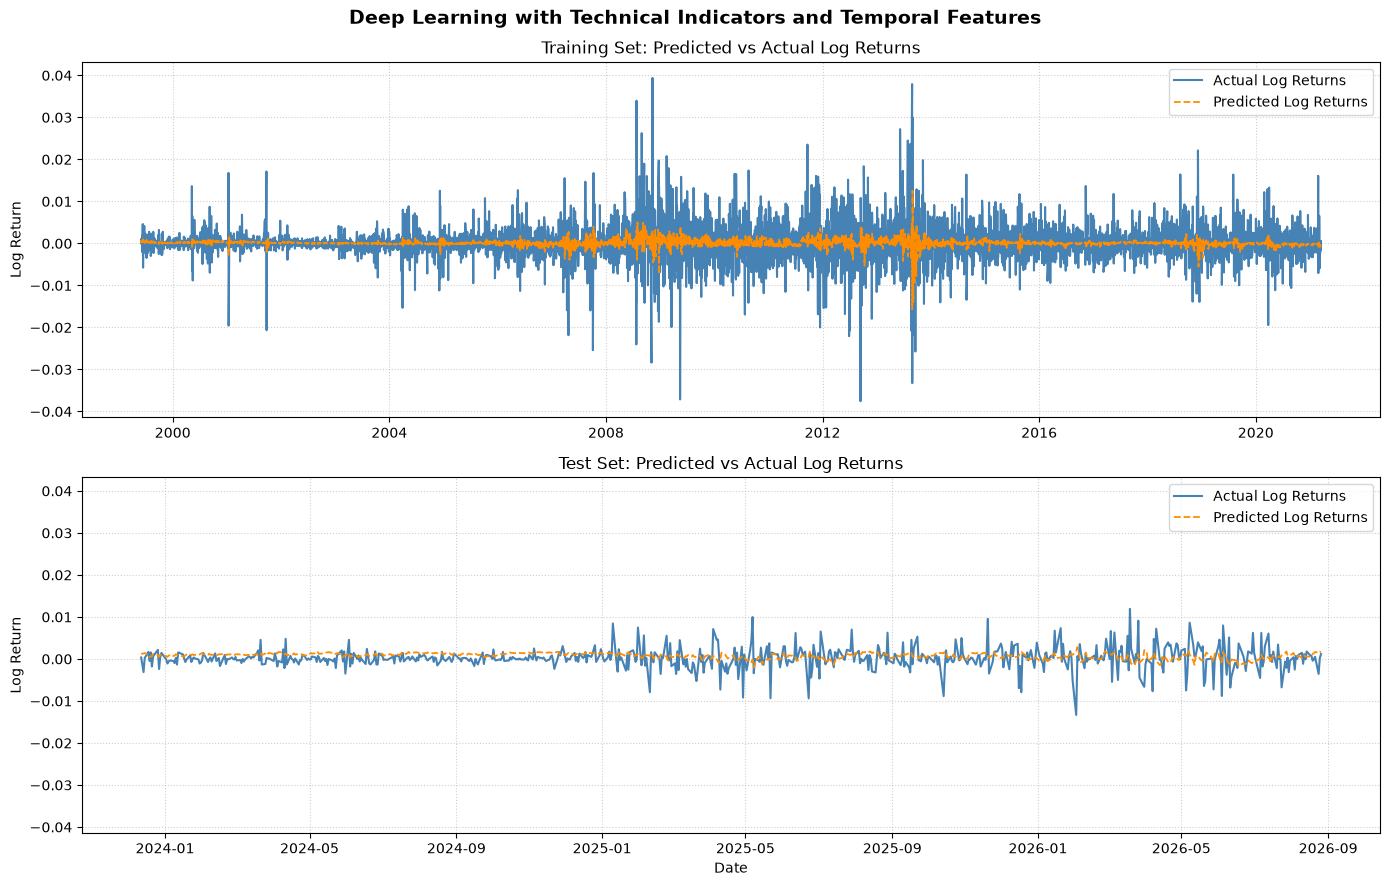

In [27]:
# PLOT PREDICTED LOG RETURNS vs ACTUAL LOG RETURNS
import matplotlib.pyplot as plt

predicted_train_log_returns = np.log(
    predicted_train_prices_temp / train_df_temp["INR"].to_numpy()
)
actual_train_log_returns = np.log(
    actual_train_prices_temp / train_df_temp["INR"].to_numpy()
)
predicted_test_log_returns = np.log(
    predicted_prices_temp / test_df_temp["INR"].to_numpy()
)
actual_test_log_returns = np.log(
    actual_prices_temp / test_df_temp["INR"].to_numpy()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

axes[0].plot(
    train_df_temp.index,
    actual_train_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[0].plot(
    train_df_temp.index,
    predicted_train_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[0].set_title("Training Set: Predicted vs Actual Log Returns")
axes[0].set_ylabel("Log Return")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(
    test_df_temp.index,
    actual_test_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[1].plot(
    test_df_temp.index,
    predicted_test_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[1].set_title("Test Set: Predicted vs Actual Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle(
    "Deep Learning with Technical Indicators and Temporal Features",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()